# 9. Literatura consultada e implicaciones metodológicas

La revisión integra un inventario de Scopus y Web of Science, una preselección de estudios y una consulta dirigida de textos completos. Los conteos del cribado previo se presentan junto con una auditoría de las exportaciones disponibles. La documentación del inventario presenta limitaciones de trazabilidad en las cadenas originales, los motivos de exclusión por registro y la revisión independiente.

Las extracciones verificadas comprenden Time-MMD, NSW-EPNews, Tan y colaboradores, Lago y colaboradores, REST-TS, TeR-TSF y TimesX. El directorio `literature/` registra versiones, fuentes, huellas y localizadores de resultados. La caracterización de modelos de referencia se fundamenta en su descripción metodológica en texto completo.

In [1]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from IPython.display import Markdown, display
import json
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'tables').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.4), 'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18, 'axes.prop_cycle': plt.cycler(color=['#245b8d', '#d17a32', '#2b8c77', '#8c5da8', '#9a4949'])})
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda x: f'{x:.5g}')

In [3]:
def decision(preprocess, architecture, validation, risk):
    display(Markdown('### Implicaciones del análisis\n\n' + '\n'.join(('- **' + a + ':** ' + b for a, b in [('Preprocesamiento', preprocess), ('Arquitectura', architecture), ('Validación', validation), ('Riesgos', risk)]))))

In [4]:
def figure(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [5]:
def table(frame, name):
    frame.to_csv(RESULTS / 'tables' / (name + '.csv'), index=True)
    display(frame)
    return None

In [6]:
import json
meta = json.loads((ROOT / 'literature/inherited_prisma_counts.json').read_text(encoding='utf-8'))
counts = pd.Series({k: meta[k] for k in ['registros_exportados', 'scopus', 'wos', 'unicos', 'seleccionados']}, name='inventario_previo')
table(counts.to_frame(), 'literatura_inventario_previo')

,inventario_previo
registros_exportados,855
scopus,562
wos,293
unicos,668
seleccionados,83


In [7]:
audit = json.loads((ROOT / 'literature/raw_export_audit.json').read_text(encoding='utf-8'))
table(pd.DataFrame({'exportación_actual': [audit['scopus_current_publication_ids'], audit['wos_current_records']], 'inventario_previo': [audit['inherited_scopus_count'], audit['inherited_wos_count']]}, index=['Scopus', 'Web of Science']), 'literatura_conciliacion_exportaciones')

,exportación_actual,inventario_previo
Scopus,615,562
Web of Science,293,293


In [8]:
display(Markdown(f"La exportación actual de Scopus contiene **{audit['scopus_current_publication_ids']}** identificadores distintos, mientras el inventario previo registra **{audit['inherited_scopus_count']}**. La diferencia de **{audit['scopus_difference']}** registros no está conciliada por artículo. El inventario previo y la exportación actual se presentan por separado hasta completar su conciliación."))

La exportación actual de Scopus contiene **615** identificadores distintos, mientras el inventario previo registra **562**. La diferencia de **53** registros no está conciliada por artículo. El inventario previo y la exportación actual se presentan por separado hasta completar su conciliación.

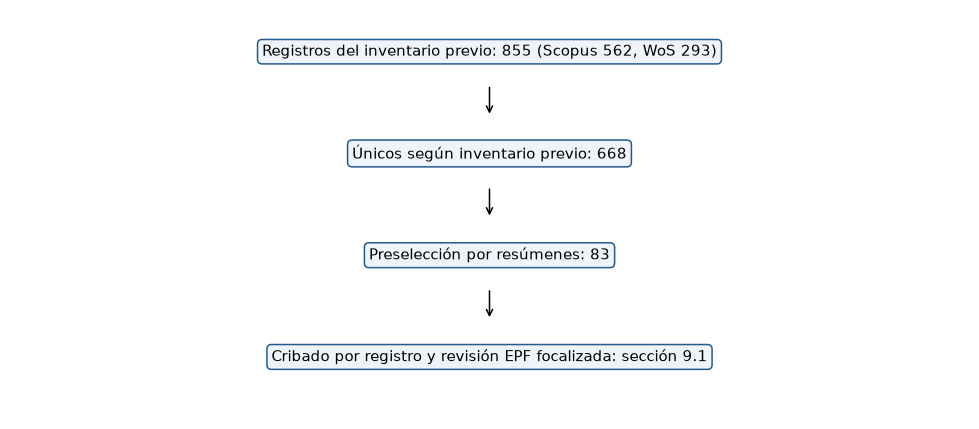

In [9]:
selected = pd.read_csv(ROOT / 'literature/inherited_selected_83.csv')
fig, ax = plt.subplots(figsize=(9, 4))
ax.axis('off')
boxes = [(0.9, f"Registros del inventario previo: {meta['registros_exportados']} (Scopus {meta['scopus']}, WoS {meta['wos']})"), (0.65, f"Únicos según inventario previo: {meta['unicos']}"), (0.4, f"Preselección por resúmenes: {meta['seleccionados']}"), (0.15, 'Cribado por registro y revisión EPF focalizada: sección 9.1')]
for y, label in boxes:
    ax.text(0.5, y, label, ha='center', va='center', bbox=dict(boxstyle='round', fc='#eef4fa', ec='#245b8d'))
for y in [0.82, 0.57, 0.32]:
    ax.annotate('', xy=(0.5, y - 0.08), xytext=(0.5, y), arrowprops=dict(arrowstyle='->'))
figure(fig, 'flujo_bibliografico_parcial')

## Resultados extraídos de los estudios

La tabla sintetiza resultados publicados junto con su problema, conjunto de datos, modelos y métricas. Las diferencias de escala, frecuencia, horizonte y protocolo requieren interpretar cada resultado en su contexto experimental.


In [10]:
verified = pd.read_csv(ROOT / 'literature/verified_extracts.csv')
table(verified, 'literatura_resultados_verificados')

,referencia,problema,dataset,modelos_comparados_verificados,metrica,valores_reportados,localizador,url,limite_de_comparabilidad
0,"Liu et al. (2024), Time-MMD",Pronóstico multimodal,Energy: gasolina semanal,DLinear uni/multimodal; otros backbones,MSE,H=12: 0.26 unimodal; 0.22 multimodal,"Tabla 12, p.33 del PDF v2",https://arxiv.org/pdf/2406.08627v2,Escala del benchmark; no COP ni precio eléctrico.
1,Tan et al. (2024),Ablación del LLM sobre series numéricas,ETTh1; promedio de horizontes de la tabla,Time-LLM; sin LLM; atención; Transformer,MSE,Time-LLM 0.417; sin LLM 0.405,"Tabla 3, p.6 del PDF v2",https://arxiv.org/pdf/2406.16964v2,No evalúa añadir noticias exógenas; no demuest...
2,"Bi et al. (2025), NSW-EPNews",Pronóstico de precio eléctrico con texto/clima,NSW 2015–2024; subconjunto reciente 50%,ARIMA; LR; XGBoost; ChatGPT-4o; Gemini 1.5 Pro,MAE,ARIMA 54.579; ChatGPT-4o zero-shot 53.646; abl...,"Tabla 2, p.7; definición de ablation tabla 1",https://arxiv.org/pdf/2506.11050v1,Ablación elimina noticias y temperatura; no aí...
3,Lago et al. (2021),Precio eléctrico del día siguiente,"NP, ejemplo de cinco mercados",DNN feed-forward; LEAR regularizado,MAE,DNN3 1.712; LEAR84 1.952,"Tabla 2, p.15",https://doi.org/10.1016/j.apenergy.2021.116983,Unidades del mercado original; no trasladar el...
4,"Nguyen et al. (2026), REST-TS",Fusión multimodal y text collapse,"Time-MMD; TimeBridge, promedio de horizontes",Unimodal; MM-TSFLib; TaTS; REST-TS,MSE,Energy: TaTS 0.297; REST-TS 0.261. Traffic: 0....,"Tabla 1, p.7",https://arxiv.org/pdf/2606.19413,No mejora en toda combinación; separar utilida...
5,"Su et al. (2025), TeR-TSF",Refuerzo de texto para pronóstico,"Time-MMD, promedio entre dominios",TSF-only; TSF+Text; TSF+TeR; TeR-TSF,MSE,"0.771; 0.768; 0.953; 0.631, respectivamente","Tabla 2, p.7",https://arxiv.org/pdf/2509.00687,Promedios de dominios y configuración del artí...
6,"Liu et al. (2026), TimesX",Auditoría de evaluación multimodal,"Time-MMD, reemplazo de contexto textual",LLM con contexto original y con contexto de lo...,MASE agregada geométrica,Contexto original 0.906; contexto de autores 0...,Tabla 3 y apéndice S,https://arxiv.org/pdf/2607.06973,"El contraste cambia contexto, no sólo arquitec..."


**Time-MMD.** Integra series numéricas y texto alineado en varios dominios. La comparación de DLinear en Energy aporta evidencia sobre la incorporación de información textual en una serie semanal de gasolina. Su aplicación al precio eléctrico requiere evaluar cobertura, fechas de publicación y estabilidad de las versiones documentales. [Texto completo, apéndices D.4, K y tabla 12](https://arxiv.org/pdf/2406.08627v2).

**Tan y colaboradores.** Las ablaciones reemplazan o retiran el LLM en modelos alimentados por series numéricas. Sus resultados fundamentan la inclusión de referencias numéricas fuertes y evaluaciones del aporte de cada componente bajo presupuestos comparables. [Texto completo, secciones 3–4 y tabla 3](https://arxiv.org/pdf/2406.16964v2).

**NSW-EPNews.** Combina precios eléctricos, temperatura y noticias. El desempeño depende del modelo y de la configuración. La ablación retira simultáneamente noticias y temperatura; para estimar el aporte específico del texto se requiere mantener constantes las covariables numéricas. [Texto completo, secciones 3–4, tablas 1–2 y apéndice C](https://arxiv.org/pdf/2506.11050v1).

**Lago y colaboradores.** Comparan redes densas y regresión autorregresiva regularizada en distintos mercados eléctricos. El benchmark fundamenta la evaluación temporal, la inclusión de referencias competitivas y el reporte conjunto de errores absolutos y relativos. [Texto completo, secciones 3–6 y tabla 2](https://doi.org/10.1016/j.apenergy.2021.116983).

**REST-TS.** Examina la sensibilidad de la rama textual y propone supervisión sobre residuos. La variación de resultados entre dominios fundamenta las ablaciones con texto placebo y las comparaciones con una estructura numérica común. [Texto completo, secciones 3–4 y tabla 1](https://arxiv.org/pdf/2606.19413).

**TeR-TSF.** Compara texto original, generado y ajustado mediante refuerzo. La sensibilidad al procedimiento de generación destaca la importancia de conservar la procedencia del texto y separar los datos utilizados en el ajuste y la evaluación. [Texto completo, método y tabla 2](https://arxiv.org/pdf/2509.00687).

**TimesX.** Analiza el efecto de sustituir el contexto textual y los riesgos de contaminación asociados al preentrenamiento. Sus resultados fundamentan el control de versiones y la igualdad de información disponible entre modelos. [Texto completo, sección 3, tabla 3 y apéndice S](https://arxiv.org/pdf/2607.06973).

## Documentación complementaria

Los planes de investigación del programa orientan la documentación de fuentes, cobertura, calidad y diccionario de variables. La lista de artículos y datasets aportada se incorpora como inventario bibliográfico complementario. La síntesis de resultados utiliza las extracciones verificadas en los artículos completos.

## Implicaciones para el diseño del pronóstico

Las familias MLP, LSTM y CNN1D ofrecen representaciones complementarias de las relaciones entre rezagos, la memoria temporal y los patrones locales. La revisión focalizada de las secciones 9.1–9.2 verifica su uso como referencia y fundamenta su selección conjunta mediante frecuencia, estructura y costo.

La evaluación del aporte textual requiere comparar modelos con el mismo bloque numérico, los mismos orígenes y una política común de disponibilidad. Los mecanismos de agrupamiento y fusión deben ajustarse con entrenamiento. La incertidumbre sobre versiones retrospectivas se incorpora al análisis de sensibilidad del diseño experimental.


## 9.1 Revisión de uso efectivo como referencia comparativa

La pregunta de esta revisión es qué familias neuronales numéricas se utilizan como referencias comparativas para pronosticar precios eléctricos. Se examinan estudios empíricos y benchmarks cuyo problema principal es el precio eléctrico continuo, con datos reales y texto completo disponible entre 2018 y el 6 de noviembre de 2026. El componente empírico de Lago et al. (2021) se incluye como benchmark; su síntesis secundaria no aporta observaciones adicionales.

El cribado por título y resumen de los 83 registros heredados no identificó estudios centrados en esta comparación. Los métodos generales, el pronóstico de demanda o pérdidas y los estudios financieros se conservan como contexto del proyecto multimodal. Cada decisión y su motivo se registran en [screening_inherited.csv](https://github.com/Fabian-11037/Time-Series-Project/blob/main/literature/baseline_review/screening_inherited.csv). Esto no significa que se hayan revisado 83 textos completos.

Se realizó una búsqueda pública complementaria mediante títulos exactos y combinaciones de *electricity price forecasting*, *MLP/DNN*, *LSTM*, *CNN*, *benchmark* y *baseline*, seguida de recuperación en editoriales, repositorios institucionales, sitios de autores, arXiv y Europe PMC. La búsqueda es focalizada y su cobertura no es exhaustiva. El [registro de recuperación](https://github.com/Fabian-11037/Time-Series-Project/blob/main/literature/baseline_review/retrieval_registry.csv) conserva tanto los textos examinados como los candidatos pendientes. Las frecuencias describen el corpus recuperado; no estiman la prevalencia en toda la disciplina.

La unidad de conteo es el **estudio único por familia**. Varios mercados, tamaños, semillas o configuraciones aportan una sola presencia. Se incluyen modelos efectivamente evaluados como comparadores y referencias de benchmarks sin arquitectura original propia. Se excluyen del conteo estricto las propuestas, los componentes, los controles de ablación y las menciones bibliográficas. Se mantiene en el denominador todo estudio empírico elegible, incluso cuando sólo compara variantes de su propuesta o no utiliza ninguna de las tres familias seleccionadas.

MLP y DNN feed-forward simples se agrupan; LSTM, GRU, RNN simple, BiLSTM, TCN y Transformers se distinguen. Un híbrido conserva su familia propia. N-BEATSx y N-HiTS no se convierten en MLP por sus capas densas internas. CNN agrupa la referencia convolucional independiente; la dimensión se audita por separado antes de vincularla con CNN1D. Las arquitecturas preentrenadas conservan su identificador de modelo, con sus tamaños colapsados. Los estratos probabilístico y de precio de regulación/capacidad se analizan aparte del pronóstico puntual de energía.


In [11]:
review_dir = ROOT / 'literature/baseline_review'
studies = pd.read_csv(review_dir / 'studies.csv', keep_default_na=False)
extractions = pd.read_csv(review_dir / 'extractions.csv', keep_default_na=False)
screening = pd.read_csv(review_dir / 'screening_inherited.csv', keep_default_na=False)
retrieval = pd.read_csv(review_dir / 'retrieval_registry.csv', keep_default_na=False)
assert studies.study_id.is_unique
assert screening.record_id.is_unique and len(screening) == 83
assert set(extractions.study_id) <= set(studies.study_id)
assert extractions.merge(studies[['study_id', 'sha256']], on='study_id', suffixes=('_extract', '_study')).eval('sha256_extract == sha256_study').all()
empirical_ids = set(studies.loc[studies.estrato != 'contexto_revision', 'study_id'])
point_ids = set(studies.loc[studies.estrato == 'puntual', 'study_id'])
peer_point_ids = set(studies.loc[(studies.estrato == 'puntual') & (studies.preprint == 0), 'study_id'])
flow = pd.DataFrame([['Inventario heredado: cribado por título/resumen', len(screening)], ['Inventario heredado: incluidos en frecuencia EPF', 0], ['Búsqueda complementaria: textos completos examinados', len(studies)], ['Estudios empíricos de pronóstico puntual', len(point_ids)], ['Sensibilidad: mercado relacionado', int((studies.estrato == 'mercado_relacionado').sum())], ['Sensibilidad: pronóstico probabilístico', int((studies.estrato == 'probabilistico').sum())], ['Revisión secundaria excluida del conteo', int((studies.estrato == 'contexto_revision').sum())], ['Candidatos pendientes de texto íntegro', int((retrieval.estado == 'pendiente_texto_completo').sum())]], columns=['etapa', 'estudios_o_registros'])
table(flow, 'literatura_flujo_revision_baselines')

,etapa,estudios_o_registros
0,Inventario heredado: cribado por título/resumen,83
1,Inventario heredado: incluidos en frecuencia EPF,0
2,Búsqueda complementaria: textos completos exam...,20
3,Estudios empíricos de pronóstico puntual,16
4,Sensibilidad: mercado relacionado,1
5,Sensibilidad: pronóstico probabilístico,2
6,Revisión secundaria excluida del conteo,1
7,Candidatos pendientes de texto íntegro,5


In [12]:
table(screening.groupby('codigo_motivo').size().to_frame('registros'), 'literatura_exclusiones_83')

,registros
codigo_motivo,
duplicado,1
metodo_general,13
otra_tarea,3
otra_variable_energetica,4
otro_dominio,58
revision,4


In [13]:
table(studies[['study_id', 'referencia', 'estrato', 'identificador']], 'literatura_estudios_baselines')

,study_id,referencia,estrato,identificador
0,lago_2018,Lago et al. (2018),puntual,10.1016/j.apenergy.2018.02.069
1,lago_2021,Lago et al. (2021),puntual,10.1016/j.apenergy.2021.116983
2,ugurlu_2018,Ugurlu et al. (2018),puntual,10.3390/en11051255
3,kuo_2018,Kuo y Huang (2018),mercado_relacionado,10.3390/su10041280
4,ghimire_2024,Ghimire et al. (2024; online 2023),puntual,10.1016/j.apenergy.2023.122059
5,d3net_2025,Ghimire et al. (2025),puntual,10.1016/j.egyai.2025.100492
6,stl_tcn_2023,Zhang et al. (2023),puntual,10.1016/j.heliyon.2023.e13029
7,rl_ensemble_2026,Wang et al. (2026),puntual,10.3390/en19030761
8,crossborder_2026,"Elashhab et al. (2026), preprint v1",puntual,arXiv:2608.17091v1
9,attention_2024,Laitsos et al. (2024),puntual,10.3390/en17071625


### Frecuencias y análisis de sensibilidad

El conteo estricto utiliza 16 estudios de pronóstico puntual. La sensibilidad sin preprints conserva 14; la ampliada incorpora un estudio de regulación/capacidad y dos probabilísticos, para 19 estudios empíricos. El porcentaje de cada familia utiliza el denominador de su columna; como un artículo puede evaluar varias familias, los porcentajes no suman 100 %. Un cero representa ausencia de comparadores verificados en ese estrato, sin atribuir ausencias a artículos inaccesibles.


In [14]:
allowed_roles = {'comparador', 'comparador_benchmark'}
baselines = extractions.loc[extractions.papel.isin(allowed_roles) & (extractions.modelo_neuronal_objetivo == 1)].copy()
presence = baselines[['study_id', 'familia']].drop_duplicates()
families = sorted(presence.familia.unique())

def study_frequency(study_ids):
    return presence.loc[presence.study_id.isin(study_ids)].groupby('familia').study_id.nunique().reindex(families, fill_value=0).astype(int)
frequency = pd.DataFrame({'estudios_puntuales': study_frequency(point_ids), 'estudios_puntuales_sin_preprints': study_frequency(peer_point_ids), 'estudios_ampliados': study_frequency(empirical_ids)})
frequency['porcentaje_puntual'] = (100 * frequency.estudios_puntuales / len(point_ids)).round(2)
frequency['denominador_puntual'] = len(point_ids)
frequency['denominador_sin_preprints'] = len(peer_point_ids)
frequency['denominador_ampliado'] = len(empirical_ids)
frequency = frequency.sort_values(['estudios_puntuales', 'familia'], ascending=[False, True])
saved = pd.read_csv(review_dir / 'baseline_frequencies.csv').set_index('familia')
pd.testing.assert_frame_equal(frequency.sort_index(), saved[frequency.columns].sort_index(), check_dtype=False)
assert (frequency.estudios_puntuales <= len(point_ids)).all()
assert len(presence.query("study_id == 'd3net_2025' and familia == 'MLP/DNN'")) == 1
assert not len(presence.query("study_id == 'lago_2018' and familia == 'CNN'"))
assert not len(presence.query("study_id == 'ghimire_2024' and familia == 'CNN'"))
assert not len(presence.query("study_id == 'multibranch_2026'"))
assert 'LSTM-FFEC' in set(presence.loc[presence.study_id == 'less_more_2026', 'familia'])
table(frequency[['estudios_puntuales', 'porcentaje_puntual', 'estudios_puntuales_sin_preprints', 'estudios_ampliados']], 'literatura_frecuencias_baseline')

,estudios_puntuales,porcentaje_puntual,estudios_puntuales_sin_preprints,estudios_ampliados
familia,,,,
LSTM,7,43.75,6,9
MLP/DNN,6,37.5,6,8
CNN,2,12.5,2,4
CNN-LSTM,2,12.5,2,2
Transformer,2,12.5,1,3
...,...,...,...,...
Mitra+CP,0,0,0,1
Moirai-2,0,0,0,1
TabPFN,0,0,0,1


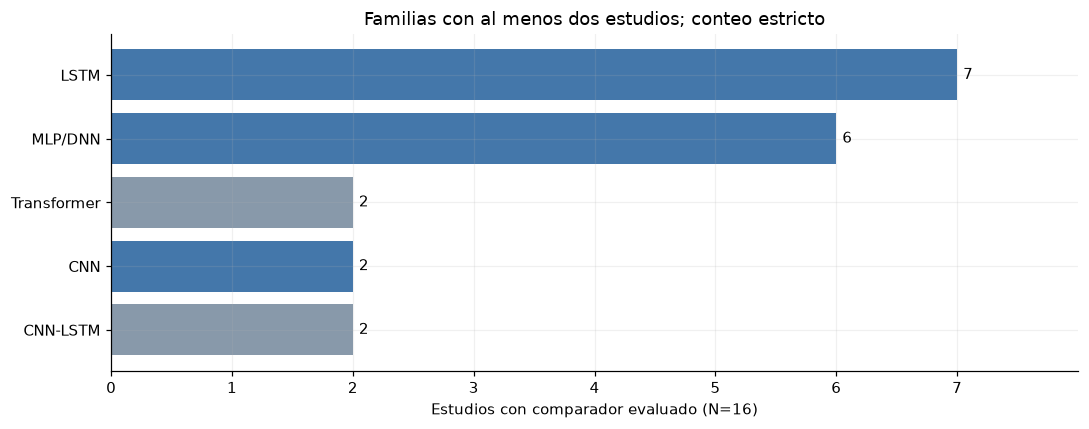

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
plotted = frequency.loc[frequency.estudios_puntuales >= 2, 'estudios_puntuales'].sort_values()
ax.barh(plotted.index, plotted.values, color=['#4477aa' if f in {'MLP/DNN', 'LSTM', 'CNN'} else '#8899aa' for f in plotted.index])
ax.set(xlabel=f'Estudios con comparador evaluado (N={len(point_ids)})', title='Familias con al menos dos estudios; conteo estricto')
ax.set_xticks(range(0, int(plotted.max()) + 1))
for i, value in enumerate(plotted.values):
    ax.text(value + 0.05, i, str(value), va='center')
ax.set_xlim(0, plotted.max() + 1)
figure(fig, 'frecuencia_baselines_texto_completo')

In [16]:
core_simple = baselines.loc[baselines.study_id.isin(point_ids) & baselines.familia.isin(['MLP/DNN', 'LSTM', 'CNN'])]
membership = pd.crosstab(core_simple.referencia, core_simple.familia).gt(0).astype(int)
table(membership, 'literatura_matriz_tres_familias')

familia,CNN,LSTM,MLP/DNN
referencia,,,
"Elashhab et al. (2026), preprint v1",0,1,0
Ghimire et al. (2024; online 2023),0,1,1
Ghimire et al. (2025),1,1,1
Khalid et al. (2020; online 2019),0,1,0
Lago et al. (2018),0,0,1
Lago et al. (2021),0,0,1
Ugurlu et al. (2018),1,1,1
Zamee et al. (2024),0,1,1
Zhang et al. (2023),0,1,0


In [17]:
cnn_1d_ids = set(baselines.loc[(baselines.familia == 'CNN') & (baselines.dimension_convolucion == '1D'), 'study_id']) & point_ids
dimension_audit = pd.DataFrame({'estudios': [len(cnn_1d_ids), len(set(core_simple.loc[core_simple.familia == 'CNN', 'study_id']) - cnn_1d_ids)]}, index=['CNN con dimensión 1D explícita', 'CNN con dimensión no reportada'])
table(dimension_audit, 'literatura_dimension_cnn')

,estudios
CNN con dimensión 1D explícita,1
CNN con dimensión no reportada,1


LSTM aparece en **7/16 estudios (43,75 %)** y MLP/DNN en **6/16 (37,50 %)**. CNN independiente aparece en **2/16 (12,50 %)**, empatada con CNN-LSTM y Transformer. Por tanto, la frecuencia por sí sola no determina un tercer modelo único. Al retirar preprints se obtienen 6/14 para LSTM y MLP/DNN y 2/14 para CNN; al ampliar mercados y objetivos, las cifras pasan a 9/19, 8/19 y 4/19, respectivamente.

En la evidencia principal de CNN, Ugurlu et al. especifican convoluciones unidimensionales; D3Net no permite confirmar la dimensión del comparador independiente. La frecuencia estrictamente verificable de **CNN1D es 1/16**. La elección de una implementación temporal unidimensional se fundamenta en esa referencia y en la estructura horaria de la entrada, sin atribuir a todas las CNN la misma configuración.

La clasificación de controles modifica el resultado: si se incluyera la GRU de una capa de Ugurlu et al. como referencia de profundidad, GRU pasaría de 1/16 a 2/16. La tabla principal la conserva como ablación de la propuesta multicapa. Asimismo, la LSTM abreviada en *Less Is More* incorpora corrección feed-forward en su figura 6 y se registra como LSTM-FFEC. El perceptrón sin capa oculta de Laitsos et al., las ramas de la metarred de Radziukyniene et al. y las arquitecturas CNN-BiLSTM-AR o CNN-LSTM con pérdidas modificadas no aportan presencias a sus componentes.

### Configuraciones, resultados y calidad de la evidencia

La extracción conserva arquitectura, regularización, entrenamiento, resultados y páginas o tablas. **NR** significa que la especificación no se reporta de forma suficiente para reproducir ese comparador; no se completa con parámetros del modelo propuesto. Las métricas se mantienen en su mercado, caso y escala. No se promedian errores entre monedas, horizontes o conjuntos de datos.


In [18]:
configuration = core_simple[['referencia', 'modelo', 'arquitectura', 'regularizacion', 'entrenamiento', 'localizador']]
table(configuration, 'literatura_configuraciones_baselines')

,referencia,modelo,arquitectura,regularizacion,entrenamiento,localizador
0,Lago et al. (2018),MLP,1 capa oculta; 117 neuronas; salida horaria,NR,Optimización descrita con referencias al apénd...,"§4.3, tabla 7 (PDF p.12), §5.7.3.2 (p.18)"
5,Lago et al. (2021),DNN1–DNN4,"2 capas ocultas; 24 salidas; ancho, activación...",Dropout y L1 como hiperparámetros; valores por...,Adam; TPE 1500 iteraciones; early stopping; re...,"§4.3 (PDF pp.9–10), tabla 2 (p.14)"
7,Ugurlu et al. (2018),ANN 1 y 3 capas,1×10 o 3×10 unidades; salida densa,NR,Adam; lr 0.001; momentum reportado 0.90; MAE; ...,§3.1 p.8; tablas 3–4 p.13; §4.5 p.16
8,Ugurlu et al. (2018),LSTM 1 y 3 capas,1 o 3 capas recurrentes y salida densa; ancho NR,NR,Adam; lr 0.001; momentum reportado 0.90; MAE; ...,§3.3 pp.8–10; tablas 3–4 p.13; §4.5 p.16
9,Ugurlu et al. (2018),CNN,2 convoluciones unidimensionales con pooling y...,NR,Adam; lr 0.001; momentum reportado 0.90; MAE; ...,§3.2 p.8; tabla 3 p.13; §4.5 p.16
16,Ghimire et al. (2024; online 2023),DNN,"3 capas; rangos publicados 50:150:5,50:80:5 y ...",NR,"Adam; 1000 épocas; batch range(50,1500,200); H...",Tabla B.12 p.24; tabla C.13 p.31
17,Ghimire et al. (2024; online 2023),LSTM,2 capas/celdas; rangos 50:100:5 y 50:80:5; ReLU,"Dropout 0–0.5, paso 0.1 reportado","1000 épocas; batch range(50,1500,200); HPO bay...",Tabla B.12 p.24; tabla C.13 p.31
21,Ghimire et al. (2025),MLP,1 capa oculta; 50/60/70/80/90/100; ReLU/logist...,NR,Adam; lr 0.001/0.002/0.005/0.006; Optuna,Tabla 4 p.14; tabla 5 p.16
22,Ghimire et al. (2025),DNN,"3 capas; rangos 50:120:5,50:100:5,50:80:5",NR,"Adam; 1000 épocas; batch range(50,1500,50); Op...",Tabla 4 p.14; tabla 5 p.16
23,Ghimire et al. (2025),LSTM,2 capas/celdas; rangos 50:100:5 y 50:80:5; ReLU,"Dropout 0–0.5, paso 0.1 reportado","1000 épocas; batch range(50,1500,200); Optuna",Tabla 4 p.14; tabla 5 p.16


In [19]:
table(core_simple[['referencia', 'modelo', 'metrica', 'valor', 'caso_y_unidad', 'localizador']], 'literatura_resultados_baselines')

,referencia,modelo,metrica,valor,caso_y_unidad,localizador
0,Lago et al. (2018),MLP,sMAPE (%),13.27,Bélgica; prueba; porcentaje,"§4.3, tabla 7 (PDF p.12), §5.7.3.2 (p.18)"
5,Lago et al. (2021),DNN1–DNN4,MAE,1.712,"Nord Pool, DNN3; moneda/MWh del mercado","§4.3 (PDF pp.9–10), tabla 2 (p.14)"
7,Ugurlu et al. (2018),ANN 1 y 3 capas,MAE,6.37,"Tabla 3, F1–4; EUR/MWh",§3.1 p.8; tablas 3–4 p.13; §4.5 p.16
8,Ugurlu et al. (2018),LSTM 1 y 3 capas,MAE,5.91,"Tabla 3, F1–4; EUR/MWh",§3.3 pp.8–10; tablas 3–4 p.13; §4.5 p.16
9,Ugurlu et al. (2018),CNN,MAE,8.57,"Tabla 3, F1–4; EUR/MWh",§3.2 p.8; tabla 3 p.13; §4.5 p.16
16,Ghimire et al. (2024; online 2023),DNN,MAE,25.486,DS1; AUD/MWh,Tabla B.12 p.24; tabla C.13 p.31
17,Ghimire et al. (2024; online 2023),LSTM,MAE,22.781,DS1; AUD/MWh,Tabla B.12 p.24; tabla C.13 p.31
21,Ghimire et al. (2025),MLP,MAE,13.189,South Australia; AUD/MWh,Tabla 4 p.14; tabla 5 p.16
22,Ghimire et al. (2025),DNN,MAE,14.164,South Australia; AUD/MWh,Tabla 4 p.14; tabla 5 p.16
23,Ghimire et al. (2025),LSTM,MAE,13.330,South Australia; AUD/MWh,Tabla 4 p.14; tabla 5 p.16


In [20]:
table(studies.loc[studies.estrato != 'contexto_revision', ['referencia', 'protocolo', 'evaluacion_critica']], 'literatura_calidad_baselines')

,referencia,protocolo,evaluacion_critica
0,Lago et al. (2018),Comparación de 27 modelos; recalibración diari...,"DNN, LSTM-DNN, GRU-DNN y CNN son propuestas de..."
1,Lago et al. (2021),Componente empírico del benchmark; cuatro años...,Se incluye únicamente el experimento primario;...
2,Ugurlu et al. (2018),Comparadores estadísticos y neuronales; una y ...,La propuesta es GRU multicapa; GRU de una capa...
3,Kuo y Huang (2018),Diez segmentos; tres meses de entrenamiento y ...,No se equipara precio de capacidad/regulación ...
4,Ghimire et al. (2024; online 2023),"Ajuste bayesiano, validación para scheduler; c...",No hay CNN sola: CLSTM es híbrido. B.12 report...
5,Ghimire et al. (2025),Optuna para modelos; compara referencias simpl...,MLP y DNN aportan una sola familia. Tabla 4 es...
6,Zhang et al. (2023),Proporción train:test:verification 8:1:1; norm...,Las configuraciones de LSTM/GRU no están detal...
7,Wang et al. (2026),"Entrenamiento cronológico; compara TCN, CNN-LS...",No contiene CNN o LSTM independientes; se cons...
8,"Elashhab et al. (2026), preprint v1","Benchmark de seis arquitecturas; MAE, Adam, Op...",Preprint: cabecera contiene DOI/fechas de plan...
9,Laitsos et al. (2024),Compara arquitecturas con atención y ensambles...,Un perceptrón sin capa oculta no es MLP. CNN-G...


In [21]:
table(retrieval.loc[retrieval.estado == 'pendiente_texto_completo', ['titulo', 'identificador', 'motivo']], 'literatura_recuperacion_pendiente')

,titulo,identificador,motivo
20,An optimized deep learning approach for foreca...,10.1016/j.epsr.2024.110129,Página/editorial y ficha Yildiz; no texto comp...
21,A robust electricity price forecasting framewo...,10.1016/j.ijepes.2024.110177,Página y fragmentos; no texto íntegro recuperado.
22,Comparing time series and neural network model...,10.1016/j.rineng.2025.108465,Página y fragmentos; pendiente obtener texto í...
23,Electricity price prediction with univariate L...,10.1016/j.egyai.2026.100886,Página pública OA; volumen diciembre 2026. Fal...
24,Machine learning and deep learning prediction ...,10.1007/s43926-024-00075-4,PDF solicitado; servidor devolvió HTML Client ...


Las insuficiencias más relevantes afectan la reproducibilidad de los comparadores y la evaluación temporal. Ugurlu et al. publican dos valores distintos de CNN F1–4 en tablas 2 y 3; se conserva el 8,57 de la tabla 3 con su localizador. Ghimire et al. (2024) reportan un rango vacío para una capa DNN. Khalid et al. presentan RMSE inferior a MAE en la tabla 1, incompatible con una misma escala y muestra, y no documentan suficientemente la partición. Los trabajos con STL/VMD requieren comprobar que la descomposición no utilice observaciones futuras. Estos problemas permiten verificar presencia de una familia, pero impiden trasladar sin examen sus ganancias o configuraciones al experimento colombiano.

La revisión fue realizada mediante un único proceso de extracción; no constituye doble evaluación independiente. El acceso público, la selección focalizada, las publicaciones del mismo grupo de autores y los preprints limitan la generalización de las frecuencias. Cinco candidatos permanecen sin texto íntegro verificado y no intervienen en numerador ni denominador. El inventario heredado de Scopus/WoS continúa requiriendo conciliación; esta revisión no sustituye un flujo PRISMA completo.

## 9.2 Justificación de los tres modelos

**MLP/DNN.** Su recurrencia y el benchmark abierto de Lago et al. respaldan una referencia densa multisalida. Permite estudiar interacciones no lineales entre variables y rezagos con una estructura fácil de inspeccionar. Su debilidad es el crecimiento del número de pesos con la longitud de la ventana y la ausencia de compartición temporal. M3 utiliza dos capas ocultas de 256 y 128 unidades; sus tamaños proceden de la búsqueda colombiana, mientras la literatura fundamenta la familia y el diseño multisalida.

**LSTM.** Es la familia más recurrente del corpus y aporta memoria mediante compuertas, con parámetros compartidos a lo largo de la secuencia. L2, de una capa y 64 unidades, permite contrastar esa memoria con la representación por posiciones de MLP. La recurrencia impone procesamiento secuencial y el estado final puede comprimir en exceso la historia. La literatura no establece superioridad uniforme: el resultado depende de entradas, mercado, ventana y entrenamiento.

**CNN1D.** Se selecciona por su evidencia como comparador y por complementar los otros sesgos inductivos mediante patrones locales, pesos compartidos y procesamiento paralelo de posiciones. C3 tiene dos convoluciones de 64 filtros y kernel 5, seguidas de pooling y salida densa. CNN-LSTM combina dos mecanismos y Transformer añade atención; sus frecuencias empatadas no obligan a adoptarlos cuando se buscan exactamente tres referencias simples y diferenciadas. GRU constituye una alternativa recurrente pertinente, aunque ofrece menor contraste conceptual frente a LSTM que la convolución temporal.

La simplicidad se evalúa por estructura, número de parámetros y costo, no sólo por número de capas. Las tres configuraciones son adaptaciones al mismo horizonte de 24 horas y a 37 predictores; no reproducen exactamente un artículo. Con $p$ predictores, $L$ pasos, $H$ salidas, anchos densos $d_j$, estado recurrente $h$, $c$ filtros, kernel $k$ y pooling a $q$ posiciones, sus parámetros son

$$
P_{\mathrm{MLP}}=\sum_{j=1}^{m+1}(d_{j-1}+1)d_j,\quad d_0=Lp,\ d_{m+1}=H;
$$
$$
P_{\mathrm{LSTM}}=4h(p+h+2)+(h+1)H;
$$
$$
P_{\mathrm{CNN}}=(kp+1)c+(kc+1)c+(qc+1)H.
$$

La LSTM implementada utiliza los dos vectores de sesgo por compuerta de PyTorch. Dropout, ReLU, Softplus y pooling no incorporan parámetros entrenables. Para inferencia por ventana, el costo dominante es $O(Lpd_1+\sum d_{j-1}d_j)$ en MLP, $O(Lh(p+h)+hH)$ en LSTM y $O(Lk(pc+c^2)+qcH)$ en CNN; en las configuraciones seleccionadas $q=7$. El entrenamiento por $E$ épocas y $n$ ventanas multiplica ese orden por $En$, con factores adicionales de retropropagación y optimización. Estos órdenes no predicen por sí solos el tiempo real en CPU/GPU.


In [22]:
p, H = (37, 24)
widths = [24 * p, 256, 128, H]
mlp_parameters = sum(((a + 1) * b for a, b in zip(widths[:-1], widths[1:])))
h = 64
lstm_parameters = 4 * h * (p + h + 2) + (h + 1) * H
c, k, q = (64, 5, 7)
cnn_parameters = (k * p + 1) * c + (k * c + 1) * c + (q * c + 1) * H
complexity = pd.DataFrame([['MLP M3', 24, '256–128', mlp_parameters], ['LSTM L2', 72, '1 capa × 64', lstm_parameters], ['CNN1D C3', 24, '2 capas × 64; kernel 5', cnn_parameters]], columns=['modelo', 'historia_horas', 'estructura', 'parametros_entrenables'])
assert list(complexity.parametros_entrenables) == [263576, 27928, 43224]
table(complexity, 'literatura_complejidad_tres_modelos')

,modelo,historia_horas,estructura,parametros_entrenables
0,MLP M3,24,256–128,263576
1,LSTM L2,72,1 capa × 64,27928
2,CNN1D C3,24,2 capas × 64; kernel 5,43224


La revisión documental se realiza después de los experimentos exploratorios existentes. Sustenta la pertinencia de las familias y explicita sus adaptaciones; no convierte la selección previa de tamaños en una decisión bibliográfica a priori. Las frecuencias no incorporan los resultados colombianos ni justifican superioridad estadística. El margen práctico, el dimensionamiento y la evaluación independiente requieren su propio protocolo. La información arquitectónica insuficiente activa la condición de §3.2 del Entregable 1, que remite al procedimiento de búsqueda del Entregable 2; las 192 configuraciones exploradas no acreditan automáticamente el cumplimiento de ese requisito.

### Brecha delimitada por el corpus

Ninguno de los 16 estudios puntuales examinados evalúa conjuntamente estas tres familias en el precio horario de XM con demanda, meteorología de ocho ciudades e hidrología del SIN bajo la política de disponibilidad y los folds expansivos del proyecto. Ésta es una brecha del corpus revisado, sin afirmar ausencia universal de trabajos colombianos. El experimento permite comparar qué representación resulta adecuada para esas entradas y para los cambios de régimen observados.

Las diferencias publicadas ofrecen contexto, no un umbral transferible: Lago et al. (2018) reportan sMAPE de 13,27 % para MLP y 12,34 % para su DNN; Ugurlu et al. registran MAE de 6,37, 5,91 y 8,57 EUR/MWh para ANN, LSTM y CNN en F1–4 de la tabla 3. D3Net comunica mejoras mucho mayores frente a comparadores simples, acompañadas de descomposición y combinación de modelos cuya disponibilidad causal debe comprobarse. Cambian mercado, escala, información y presupuesto; esos resultados no fijan el margen práctico colombiano.

### Referencias de los textos completos examinados

- **Lago et al. (2018).** Forecasting spot electricity prices: Deep learning approaches and empirical comparison of traditional algorithms. [10.1016/j.apenergy.2018.02.069](https://jesuslago.com/wp-content/uploads/Lago2018b.pdf).
- **Lago et al. (2021).** Forecasting day-ahead electricity prices: A review of state-of-the-art algorithms, best practices and an open-access benchmark. [10.1016/j.apenergy.2021.116983](https://jesuslago.com/wp-content/uploads/1-s2.0-S0306261921004529-main-1.pdf).
- **Ugurlu et al. (2018).** Electricity Price Forecasting Using Recurrent Neural Networks. [10.3390/en11051255](https://mdpi-res.com/d_attachment/energies/energies-11-01255/article_deploy/energies-11-01255.pdf).
- **Kuo y Huang (2018).** An Electricity Price Forecasting Model by Hybrid Structured Deep Neural Networks. [10.3390/su10041280](https://mdpi-res.com/d_attachment/sustainability/sustainability-10-01280/article_deploy/sustainability-10-01280.pdf).
- **Ghimire et al. (2024; online 2023).** Two-step deep learning framework with error compensation technique for short-term, half-hourly electricity price forecasting. [10.1016/j.apenergy.2023.122059](https://burjcdigital.urjc.es/server/api/core/bitstreams/584ad847-68b7-4ef1-b8fb-08db68f8eeee/content).
- **Ghimire et al. (2025).** Half-hourly electricity price prediction model with explainable-decomposition hybrid deep learning approach. [10.1016/j.egyai.2025.100492](https://opus.lib.uts.edu.au/bitstream/10453/190017/2/1-s2.0-S2666546825000242-main.pdf).
- **Zhang et al. (2023).** Electricity price forecast based on the STL-TCN-NBEATS model. [10.1016/j.heliyon.2023.e13029](https://www.ebi.ac.uk/europepmc/webservices/rest/PMC9938466/fullTextXML).
- **Wang et al. (2026).** Short-Term Electricity Price Forecasting via a Reinforcement Learning-Based Dynamic Soft Ensemble Strategy. [10.3390/en19030761](https://mdpi-res.com/d_attachment/energies/energies-19-00761/article_deploy/energies-19-00761.pdf).
- **Elashhab et al. (2026), preprint v1.** Deep Learning for Cross-Border Electricity Price Forecasting: A Comparative Study. [arXiv:2608.17091v1](https://arxiv.org/pdf/2608.17091v1).
- **Laitsos et al. (2024).** Data-Driven Techniques for Short-Term Electricity Price Forecasting through Novel Deep Learning Approaches with Attention Mechanisms. [10.3390/en17071625](https://mdpi-res.com/d_attachment/energies/energies-17-01625/article_deploy/energies-17-01625.pdf).
- **Michalakopoulos et al. (2026).** Less Is More: Data-Driven Day-Ahead Electricity Price Forecasting with Short Training Windows. [10.3390/en19020376](https://mdpi-res.com/d_attachment/energies/energies-19-00376/article_deploy/energies-19-00376.pdf).
- **Radziukyniene et al. (2026).** A Multi-Parallel Hybrid Neural Network Model for Short-Term Electricity Price Forecasting Under High Market Volatility. [10.3390/app16083865](https://mdpi-res.com/d_attachment/applsci/applsci-16-03865/article_deploy/applsci-16-03865.pdf).
- **Mubarak et al. (2024).** Day-Ahead electricity price forecasting using a CNN-BiLSTM model in conjunction with autoregressive modeling and hyperparameter optimization. [10.1016/j.ijepes.2024.110206](https://research-repository.griffith.edu.au/server/api/core/bitstreams/f793f553-1e34-4690-ac7a-5822034e7878/content).
- **Wang et al. (2024).** Novel Custom Loss Functions and Metrics for Reinforced Forecasting of High and Low Day-Ahead Electricity Prices Using Convolutional Neural Network–Long Short-Term Memory (CNN-LSTM) and Ensemble Learning. [10.3390/en17194885](https://mdpi-res.com/d_attachment/energies/energies-17-04885/article_deploy/energies-17-04885.pdf).
- **Hornek et al. (2025), preprint v2.** Benchmarking Pre-Trained Time Series Models for Electricity Price Forecasting. [arXiv:2506.08113v2](https://arxiv.org/pdf/2506.08113v2).
- **Lu et al. (2026).** A Novel Probabilistic Electricity Price Forecasting Framework with Multi-Factorial Cross-Correlation Embedding and Patch Processing. [10.3390/en19102438](https://mdpi-res.com/d_attachment/energies/energies-19-02438/article_deploy/energies-19-02438.pdf).
- **Lipiecki y Weron (2026), preprint v1.** Foundation models for electricity price forecasting and battery arbitrage: Can they replace market-specific forecasting models?. [arXiv:2609.00089v1](https://arxiv.org/pdf/2609.00089v1).
- **Jasiński (2025).** A Review of Recent Trends in Electricity Price Forecasting Using Deep Learning Techniques. [10.3390/en18246422](https://mdpi-res.com/d_attachment/energies/energies-18-06422/article_deploy/energies-18-06422.pdf).
- **Khalid et al. (2020; online 2019).** Electricity Load and Price Forecasting Using Jaya-Long Short Term Memory (JLSTM) in Smart Grids. [10.3390/e22010010](https://www.ebi.ac.uk/europepmc/webservices/rest/PMC7516403/fullTextXML).
- **Zamee et al. (2024).** Self-Supervised Adaptive Learning Algorithm for Multi-Horizon Electricity Price Forecasting. [10.1109/ACCESS.2024.3389039](https://opus.lib.uts.edu.au/bitstream/10453/181427/2/Self-Supervised_Adaptive_Learning_Algorithm_for_Multi-Horizon_Electricity_Price_Forecasting.pdf).

In [23]:
decision('Estimar el preprocesamiento y las representaciones con entrenamiento; documentar cobertura y disponibilidad temporal.', 'Comparar representaciones temporales y evaluar el aporte de información adicional mediante ablaciones con una estructura numérica común.', 'Definir presupuesto, semillas, margen y protocolo de evaluación considerando la escala y frecuencia del problema.', 'La trazabilidad del inventario bibliográfico y las diferencias entre dominios condicionan la selección de referencias y la transferencia de resultados.')

### Implicaciones del análisis

- **Preprocesamiento:** Estimar el preprocesamiento y las representaciones con entrenamiento; documentar cobertura y disponibilidad temporal.
- **Arquitectura:** Comparar representaciones temporales y evaluar el aporte de información adicional mediante ablaciones con una estructura numérica común.
- **Validación:** Definir presupuesto, semillas, margen y protocolo de evaluación considerando la escala y frecuencia del problema.
- **Riesgos:** La trazabilidad del inventario bibliográfico y las diferencias entre dominios condicionan la selección de referencias y la transferencia de resultados.